# TCGA-GBM RNA-seq Analysis: Differential Expression
**Ola Hassan, PhD**

## Introduction

This notebook uses PyDESeq2 to identify genes differentially expressed between 5 GBM tumor samples and 5 normal samples.

The analysis starts from the filtered raw count matrix prepared in Notebook 2, containing 31,041 genes across 10 samples. PyDESeq2 performs count normalization, dispersion estimation, and statistical testing.

The contrast is defined as Tumor versus Normal. Positive log2 fold changes indicate higher expression in tumor samples, while negative values indicate lower expression in tumor samples.

## Objectives

- Load filtered raw counts and aligned sample metadata.
- Fit the PyDESeq2 model and test the Tumor-versus-Normal contrast.
- Annotate results with gene symbols while retaining Ensembl identifiers.
- Identify genes with adjusted p-value < 0.05 and absolute log2 fold change > 1.
- Visualize results using volcano plots, MA plots, and expression heatmaps.
- Examine selected genes relevant to glioblastoma biology.
- Export differential expression results and normalized counts.


# WorkFlow:

## 1. Import Libraries and Define Project Paths
## 2. Load and Validate Counts and Metadata
## 3. Run deseq2 using raw counts 
## 4. Test the Tumor-versus-Normal Contrast
## 5. Annotate and Summarize Results
## 6. Visualize Differential Expression
### 6.1 Volcano Plot
### 6.2 MA Plot
### 6.3 Heatmap of Selected Differentially Expressed Genes
### 6.4 Expression of Genes of Interest
## 7. Export Results and Normalized Counts
## 8. Summary and Interpretation

## 1. Import Libraries and Define Project Paths


In [7]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

PROJECT = Path("/Users/olahassan/Desktop/Python/TCGA_GBM")
DATA = PROJECT / "data_processed"
RESULTS = PROJECT / "Results"
FIGURES = PROJECT / "Figures"

for folder in [RESULTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_style("white")

condition_colors = {
    "Tumor": "#F4A6A6",
    "Normal": "#A6C8EE"
}

## 2. Load and Validate Counts and Metadata


In [9]:
# Load filtered raw counts and metadata from Notebook 2
counts = pd.read_csv(
    DATA / "count_matrix_filtered.csv",
    index_col=0
)

metadata = pd.read_csv(
    DATA / "metadata_qc.csv",
    index_col=0
)

# Check sample identifiers and align metadata
assert counts.index.is_unique
assert counts.columns.is_unique
assert metadata.index.is_unique
assert set(counts.columns) == set(metadata.index)

metadata = metadata.loc[counts.columns].copy()

# Confirm valid raw integer counts
counts = counts.apply(pd.to_numeric, errors="raise")

assert np.isfinite(counts.to_numpy()).all()
assert (counts >= 0).all().all()
assert (counts == np.floor(counts)).all().all()
assert metadata["condition"].notna().all()
assert set(metadata["condition"]) == {"Tumor", "Normal"}

counts = counts.astype("int64")

print(f"Genes: {counts.shape[0]:,}")
print(f"Samples: {counts.shape[1]}")
print(metadata["condition"].value_counts())

Genes: 31,041
Samples: 10
condition
Tumor     5
Normal    5
Name: count, dtype: int64


## 3. Run deseq2 using raw counts

In [10]:

# PyDESeq2 expects samples as rows and genes as columns

dds = DeseqDataSet(
    counts=counts.T,
    metadata=metadata,
    design="condition"
)

dds.deseq2()



Fitting size factors...
... done in 0.01 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 1.58 seconds.

Fitting dispersion trend curve...
... done in 0.26 seconds.

Fitting MAP dispersions...
... done in 1.57 seconds.

Fitting LFCs...
... done in 1.10 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.



## 4. Test Tumor vs Normal 


In [13]:
stat_res = DeseqStats(
    dds,
    contrast=["condition", "Tumor", "Normal"],
    alpha=0.05
)

stat_res.summary()



Running Wald tests...


Log2 fold change & Wald test p-value: condition Tumor vs Normal
                    baseMean  log2FoldChange     lfcSE      stat  \
gene_id                                                            
ENSG00000000003  1312.786560        1.739160  0.246737  7.048629   
ENSG00000000419  1009.315667       -0.172767  0.296846 -0.582008   
ENSG00000000457   633.743661        0.310142  0.226656  1.368338   
ENSG00000000460   256.143060        1.901388  0.359907  5.283005   
ENSG00000000938   406.212573        0.618194  0.353272  1.749909   
...                      ...             ...       ...       ...   
ENSG00000288663    35.869829       -0.660881  0.454117 -1.455312   
ENSG00000288667     4.273908        4.750657  1.702533  2.790346   
ENSG00000288670   590.927647       -1.509365  0.395253 -3.818732   
ENSG00000288674     8.628950       -0.122148  0.699480 -0.174627   
ENSG00000288675    39.716100       -0.335546  0.513585 -0.653341   

                       pvalue          padj  
gene_

... done in 0.58 seconds.



In [12]:
# Preserve the complete results with Ensembl IDs as the index
results = stat_res.results_df.copy()
results.index.name = "ensembl_id"

display(results.head())

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
ensembl_id,,,,,,
ENSG00000000003,1312.786560,1.739160,0.246737,7.048629,1.806892e-12,1.850040e-10
ENSG00000000419,1009.315667,-0.172767,0.296846,-0.582008,5.605610e-01,6.522868e-01
ENSG00000000457,633.743661,0.310142,0.226656,1.368338,1.712063e-01,2.524114e-01
ENSG00000000460,256.143060,1.901388,0.359907,5.283005,1.270817e-07,2.992676e-06
ENSG00000000938,406.212573,0.618194,0.353272,1.749909,8.013404e-02,1.355897e-01


In [14]:
# inspect the annotation file before merging it:

gene_annotation = pd.read_csv(
    DATA / "gene_annotation_GENCODE.csv"
)

print(gene_annotation.columns.tolist())
display(gene_annotation.head())

['ensembl_id', 'gene_symbol']


,ensembl_id,gene_symbol
0,ENSG00000000003,TSPAN6
1,ENSG00000000005,TNMD
2,ENSG00000000419,DPM1
3,ENSG00000000457,SCYL3
4,ENSG00000000460,C1orf112


## 5. Gene Annotation

Gene symbols are added by matching Ensembl identifiers to the annotation table from Notebook 1. Ensembl IDs remain the unique row identifiers.

Genes are classified as upregulated or downregulated in tumors using adjusted p-value < 0.05 and absolute log2 fold change > 1. Genes with missing adjusted p-values are retained and labeled separately.


In [15]:
# Prepare annotation and check for conflicting mappings
annotation = gene_annotation[
    ["ensembl_id", "gene_symbol"]
].drop_duplicates()

assert annotation["ensembl_id"].notna().all()
assert annotation["ensembl_id"].is_unique, (
    "Some Ensembl IDs have multiple annotation entries."
)

annotation = annotation.set_index("ensembl_id")

# Start from the complete statistical results
results = stat_res.results_df.copy()
results.index.name = "ensembl_id"

# Add gene symbols without changing row identifiers or order
results = results.join(
    annotation,
    how="left",
    validate="one_to_one"
)

# Classify results
results["Significant"] = "Does not meet thresholds"

results.loc[
    results["padj"].isna(),
    "Significant"
] = "Adjusted p-value unavailable"

results.loc[
    (results["padj"] < 0.05) &
    (results["log2FoldChange"] > 1),
    "Significant"
] = "Upregulated"

results.loc[
    (results["padj"] < 0.05) &
    (results["log2FoldChange"] < -1),
    "Significant"
] = "Downregulated"

# Summarize
print(results["Significant"].value_counts())
print(f"\nGenes missing symbols: {results['gene_symbol'].isna().sum():,}")

display(results.head())

# Save complete annotated results
results.to_csv(
    RESULTS / "TCGA_GBM_DESeq2_results_annotated.csv"
)



Significant
Does not meet thresholds        17412
Upregulated                      8958
Downregulated                    4244
Adjusted p-value unavailable      427
Name: count, dtype: int64

Genes missing symbols: 69


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,gene_symbol,Significant
ensembl_id,,,,,,,,
ENSG00000000003,1312.786560,1.739160,0.246737,7.048629,1.806892e-12,1.850040e-10,TSPAN6,Upregulated
ENSG00000000419,1009.315667,-0.172767,0.296846,-0.582008,5.605610e-01,6.522868e-01,DPM1,Does not meet thresholds
ENSG00000000457,633.743661,0.310142,0.226656,1.368338,1.712063e-01,2.524114e-01,SCYL3,Does not meet thresholds
ENSG00000000460,256.143060,1.901388,0.359907,5.283005,1.270817e-07,2.992676e-06,C1orf112,Upregulated
ENSG00000000938,406.212573,0.618194,0.353272,1.749909,8.013404e-02,1.355897e-01,FGR,Does not meet thresholds


### Differential Expression Summary

Using adjusted p-value < 0.05 and absolute log2 fold change > 1, 13,202 genes met both thresholds: 8,958 had higher expression and 4,244 had lower expression in tumors relative to normal samples.

An additional 17,412 genes did not meet both thresholds, and 427 had unavailable adjusted p-values. 

## 6. Visualize Differential Expression

### 6.1 Volcano Plot

The volcano plot displays log2 fold changes against −log10 adjusted p-values. Genes meeting both thresholds are highlighted by direction of change. Genes with unavailable adjusted p-values are omitted from this plot.
)

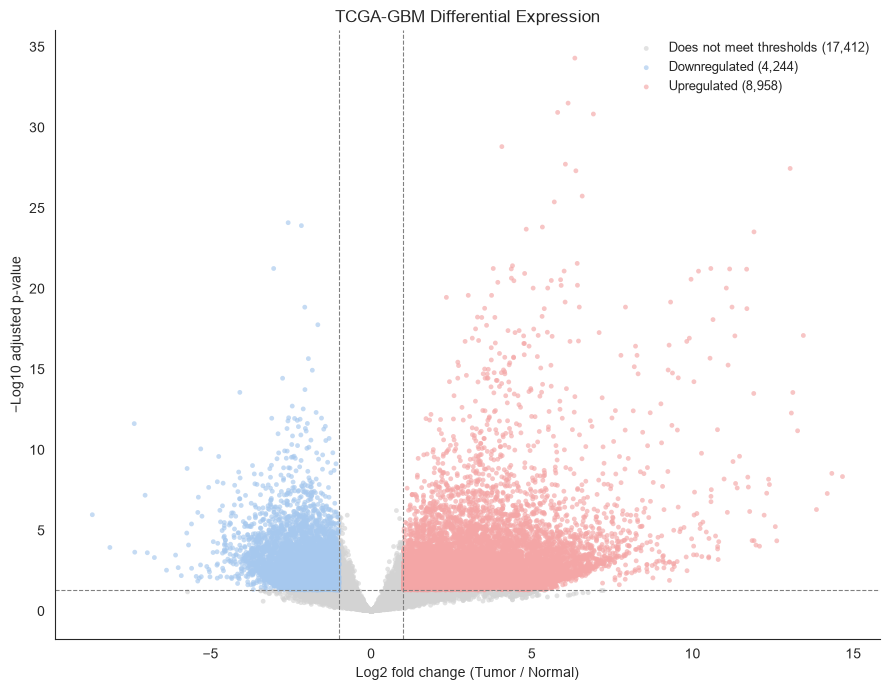

In [16]:
# Prepare a separate table for plotting
plot_data = results.loc[
    results["padj"].notna() &
    np.isfinite(results["log2FoldChange"])
].copy()

# Avoid infinite plotting values if an adjusted p-value equals zero
plot_data["minus_log10_padj"] = -np.log10(
    plot_data["padj"].clip(lower=np.finfo(float).tiny)
)

volcano_colors = {
    "Does not meet thresholds": "#D3D3D3",
    "Downregulated": "#A6C8EE",
    "Upregulated": "#F4A6A6"
}

fig, ax = plt.subplots(figsize=(9, 7))

for category, color in volcano_colors.items():
    subset = plot_data[
        plot_data["Significant"] == category
    ]

    ax.scatter(
        subset["log2FoldChange"],
        subset["minus_log10_padj"],
        color=color,
        s=12,
        alpha=0.65,
        edgecolors="none",
        label=f"{category} ({len(subset):,})"
    )

# Threshold guides
ax.axvline(-1, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(1, color="gray", linestyle="--", linewidth=0.8)
ax.axhline(
    -np.log10(0.05),
    color="gray",
    linestyle="--",
    linewidth=0.8
)

ax.set_xlabel("Log2 fold change (Tumor / Normal)")
ax.set_ylabel("−Log10 adjusted p-value")
ax.set_title("TCGA-GBM Differential Expression")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    FIGURES / "DE_Volcano_Plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Volcano Plot Interpretation

The analysis identified 8,958 genes with higher expression and 4,244 genes with lower expression in tumors using adjusted p-value < 0.05 and absolute log2 fold change > 1.


### 6.2 MA Plot

The MA plot displays log2 fold changes against mean normalized counts. It helps assess how estimated expression changes vary with gene abundance.

In [18]:
#another way to verify 

all(counts.columns == metadata.index)

True

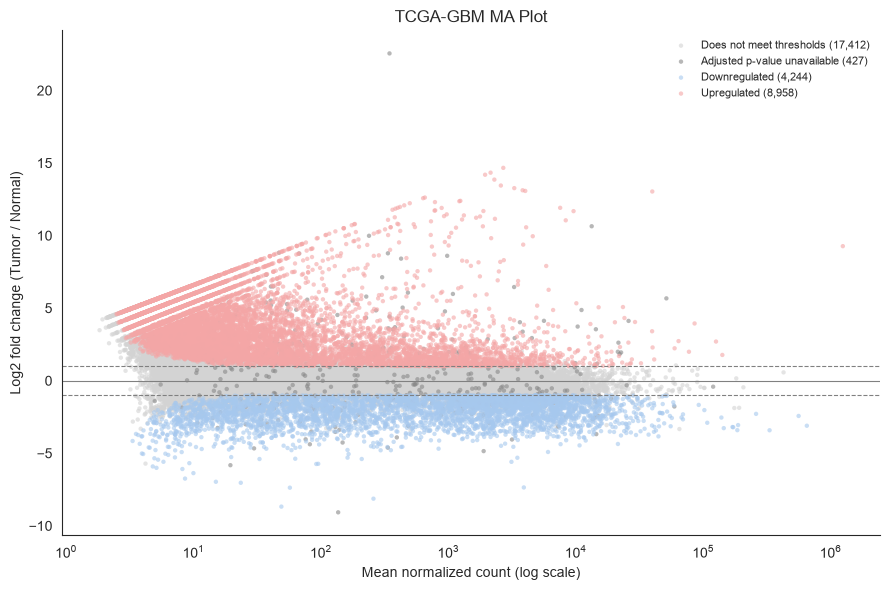

In [19]:
ma_data = results.loc[
    (results["baseMean"] > 0) &
    np.isfinite(results["baseMean"]) &
    np.isfinite(results["log2FoldChange"])
].copy()

ma_colors = {
    "Does not meet thresholds": "#D3D3D3",
    "Adjusted p-value unavailable": "#888888",
    "Downregulated": "#A6C8EE",
    "Upregulated": "#F4A6A6"
}

fig, ax = plt.subplots(figsize=(9, 6))

for category, color in ma_colors.items():
    subset = ma_data[ma_data["Significant"] == category]

    ax.scatter(
        subset["baseMean"],
        subset["log2FoldChange"],
        color=color,
        s=10,
        alpha=0.6,
        edgecolors="none",
        label=f"{category} ({len(subset):,})"
    )

ax.set_xscale("log")
ax.axhline(0, color="gray", linewidth=0.8)
ax.axhline(-1, color="gray", linestyle="--", linewidth=0.8)
ax.axhline(1, color="gray", linestyle="--", linewidth=0.8)

ax.set_xlabel("Mean normalized count (log scale)")
ax.set_ylabel("Log2 fold change (Tumor / Normal)")
ax.set_title("TCGA-GBM MA Plot")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    FIGURES / "DE_MA_Plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### MA Plot Interpretation

More genes show higher expression in tumors than lower expression, consistent with the volcano plot.

The MA plot summarizes abundance-dependent expression changes, it does not establish that normalization has removed all technical variation.

## Extract results: samples, gene symbols and ensemble ID with stats
### - Extract top 50 (by adjusted p-value) for heatmap


In [21]:
# Extract normalized counts: genes × samples
# Retain Ensembl IDs to keep expression and results aligned
normalized = pd.DataFrame(
    dds.layers["normed_counts"].T,
    index=dds.var_names,
    columns=dds.obs_names
)

normalized.index.name = "ensembl_id"

# Select genes meeting both thresholds
sig_genes = results.loc[
    (results["padj"] < 0.05) &
    (results["log2FoldChange"].abs() > 1)
].copy()

# Rank by adjusted p-value, then select 50 genes
top_genes = sig_genes.sort_values(
    ["padj", "pvalue"]
).head(50)

# Extract matching normalized expression
heatmap_data = normalized.loc[top_genes.index]

print(f"Selected genes: {len(top_genes)}")
print(f"Heatmap matrix: {heatmap_data.shape}")

display(
    top_genes[
        ["gene_symbol", "baseMean", "log2FoldChange", "padj"]
    ].head(10)
)



Selected genes: 50
Heatmap matrix: (50, 10)


,gene_symbol,baseMean,log2FoldChange,padj
ensembl_id,,,,
ENSG00000112984,KIF20A,383.807190,6.336960,5.104268e-35
ENSG00000234797,RPS3AP6,894.149077,6.127078,3.160605e-32
ENSG00000137812,KNL1,468.284577,5.801915,1.191613e-31
ENSG00000131747,TOP2A,2436.790819,6.913968,1.499767e-31
ENSG00000086991,NOX4,187.849284,4.065997,1.576378e-29
ENSG00000171848,RRM2,872.865630,6.042986,1.938190e-28
ENSG00000263740,RN7SL4P,39799.532117,13.037034,3.559164e-28
ENSG00000165304,MELK,326.522025,6.369528,4.997325e-28
ENSG00000129195,PIMREG,636.367916,6.566393,1.844869e-26


### 6.3 Heatmap of the Top 50 Differentially Expressed Genes

The 50 genes with the smallest adjusted p-values among those meeting both differential expression thresholds are displayed.

Normalized counts are transformed as log2(count + 1) and standardized within each gene using row-wise z-scores. Red indicates expression above that gene's average, and blue indicates expression below it.

Genes are clustered by expression pattern. Samples are ordered by condition, with normal samples followed by tumors. Because these genes were selected using the same condition comparison, this heatmap illustrates the identified differences rather than independently validating group separation.

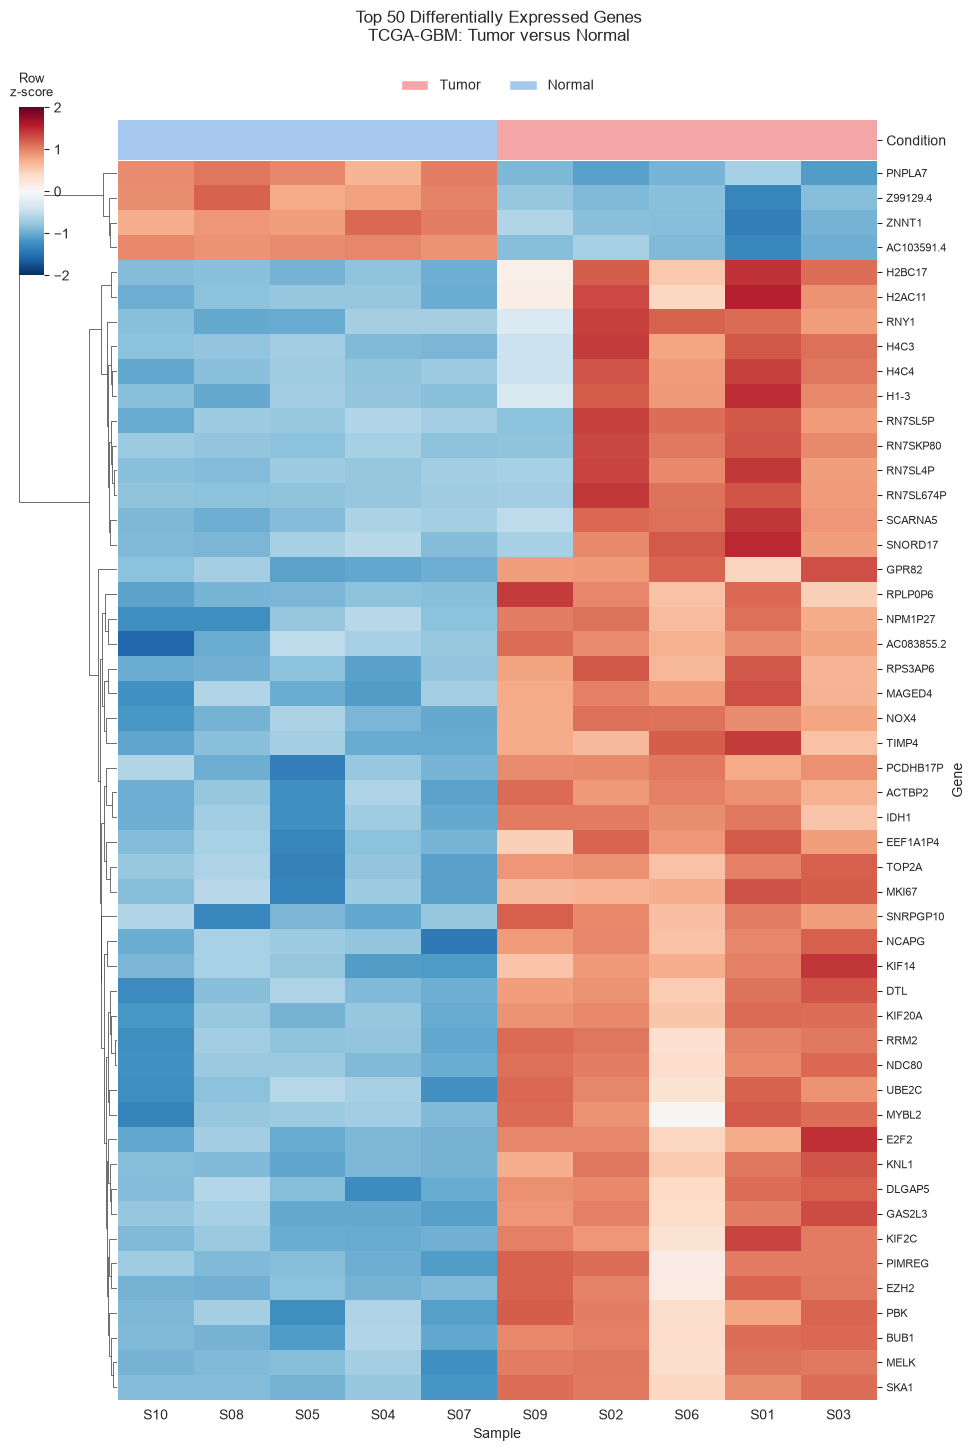

In [23]:
from matplotlib.patches import Patch

# Log-transform and standardize within each gene
heatmap_log = np.log2(heatmap_data + 1)

row_sd = heatmap_log.std(axis=1)
heatmap_log = heatmap_log.loc[row_sd > 0]

heatmap_z = (
    heatmap_log
    .sub(heatmap_log.mean(axis=1), axis=0)
    .div(heatmap_log.std(axis=1), axis=0)
)

# Order samples by condition
sample_order = (
    metadata.loc[heatmap_z.columns]
    .sort_values("condition", kind="stable")
    .index
)
heatmap_z = heatmap_z.loc[:, sample_order]

# Load the original QC sample-label mapping
qc_labels = pd.read_csv(
    DATA / "QC_sample_labels.csv",
    index_col=0
)
sample_labels = qc_labels.loc[sample_order, "plot_label"]

# Use symbols as display labels, retaining Ensembl IDs internally
symbols = results.loc[heatmap_z.index, "gene_symbol"]
gene_labels = [
    symbol if pd.notna(symbol) and str(symbol).strip() else ensembl_id
    for ensembl_id, symbol in symbols.items()
]

# Condition color strip
col_colors = metadata.loc[
    sample_order, "condition"
].map(condition_colors)
col_colors.name = "Condition"

g = sns.clustermap(
    heatmap_z,
    cmap="RdBu_r",
    center=0,
    vmin=-2,
    vmax=2,
    row_cluster=True,
    col_cluster=False,
    col_colors=col_colors,
    xticklabels=sample_labels.to_list(),
    yticklabels=gene_labels,
    figsize=(10, 14),
    dendrogram_ratio=(0.12, 0.05),
    cbar_kws={"label": "Row z-score"}
)

g.ax_heatmap.set_xlabel("Sample")
g.ax_heatmap.set_ylabel("Gene")
g.ax_heatmap.tick_params(axis="x", labelrotation=0)
g.ax_heatmap.tick_params(axis="y", labelsize=8)

g.fig.suptitle(
    "Top 50 Differentially Expressed Genes\nTCGA-GBM: Tumor versus Normal",
    y=1.02
)

g.ax_col_dendrogram.legend(
    handles=[
        Patch(facecolor=color, label=condition)
        for condition, color in condition_colors.items()
    ],
    loc="center",
    ncol=2,
    frameon=False
)

# Move the color bar above the row dendrogram
g.cax.set_position([0.02, 0.83, 0.025, 0.12])
g.cax.set_ylabel("")
g.cax.set_title("Row\nz-score", fontsize=9, pad=8)

g.savefig(
    FIGURES / "DE_Heatmap_Top50.png",
    dpi=300,
    bbox_inches="tight"
)

top_genes.to_csv(RESULTS / "Top50_DEGs.csv")

plt.show()

### Heatmap Interpretation

Most of the top 50 selected genes show higher relative expression in tumor samples than in normal samples. A smaller cluster, including PNPLA7 and ZNTT1, shows lower relative expression in tumors.

Expression varies among tumor samples, with S06 showing less pronounced increases for several genes than other tumors.


In [34]:
results.head()


,gene_id,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_symbol,,,,,,,
TSPAN6,ENSG00000000003,1310.916106,1.735695,0.255598,6.790731,1.115667e-11,1.209668e-09
TNMD,ENSG00000000005,5.385968,-0.136794,0.759379,-0.180139,8.570434e-01,8.985347e-01
DPM1,ENSG00000000419,1009.118013,-0.174900,0.306689,-0.570285,5.684845e-01,6.647768e-01
SCYL3,ENSG00000000457,633.084769,0.306104,0.235107,1.301976,1.929245e-01,2.861158e-01
C1orf112,ENSG00000000460,255.683299,1.896872,0.366085,5.181506,2.201017e-07,5.797922e-06


### 6.4 Expression of Genes of Interest

Selected genes are examined using log2-transformed PyDESeq2-normalized counts. Boxplots summarize expression within each condition, and individual points represent samples.

This panel includes HDAC7, EZH2, HIRA, EGFR, PTEN, TP53, and TERT. Statistical results for these genes are reported separately from the expression plots.

In [38]:
#Remove missing adjusted p-values

results = results.dropna(subset=["padj"])

Genes absent from the filtered results: []


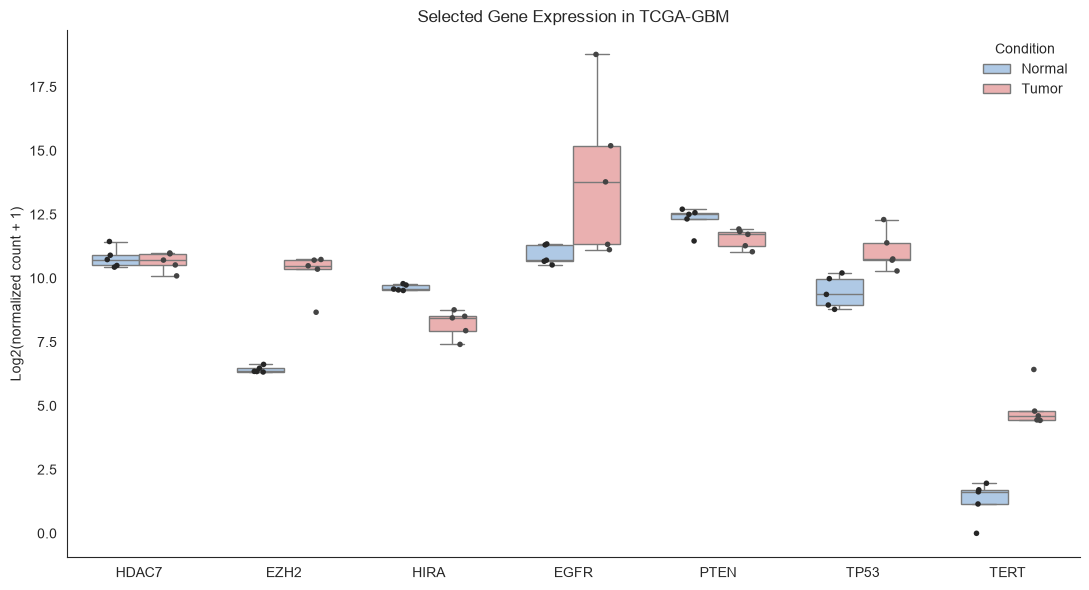

,ensembl_id,baseMean,log2FoldChange,padj,Significant
gene_symbol,,,,,
HDAC7,ENSG00000061273,1744.762000,-0.158939,6.825048e-01,Does not meet thresholds
EZH2,ENSG00000106462,694.108524,3.940070,4.134635e-21,Upregulated
HIRA,ENSG00000100084,552.281276,-1.350782,5.815490e-05,Downregulated
EGFR,ENSG00000146648,51342.687467,5.672108,NaN,Adjusted p-value unavailable
PTEN,ENSG00000171862,4194.279601,-0.774480,3.263248e-02,Does not meet thresholds
TP53,ENSG00000141510,1612.107952,1.708205,1.202641e-03,Upregulated
TERT,ENSG00000164362,18.437296,4.319072,1.249623e-06,Upregulated


In [24]:
genes_of_interest = [
    "HDAC7", "EZH2", "HIRA", "EGFR", "PTEN", "TP53", "TERT"
]

# Match symbols while retaining Ensembl identifiers
selected_results = results.loc[
    results["gene_symbol"].isin(genes_of_interest)
].copy()

missing = [
    gene for gene in genes_of_interest
    if gene not in selected_results["gene_symbol"].values
]
print("Genes absent from the filtered results:", missing)

# Check for ambiguous symbol mappings
assert not selected_results["gene_symbol"].duplicated().any(), (
    "A selected symbol maps to multiple Ensembl IDs; inspect before plotting."
)

present_genes = [
    gene for gene in genes_of_interest if gene not in missing
]
assert present_genes, "None of the selected genes were found."

# Prepare expression table
expression = np.log2(
    normalized.loc[selected_results.index] + 1
)

expression.index = selected_results["gene_symbol"]

plot_df = (
    expression.rename_axis("Gene")
    .reset_index()
    .melt(
        id_vars="Gene",
        var_name="sample",
        value_name="Expression"
    )
)

plot_df["condition"] = plot_df["sample"].map(
    metadata["condition"]
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.boxplot(
    data=plot_df,
    x="Gene",
    y="Expression",
    hue="condition",
    order=present_genes,
    hue_order=["Normal", "Tumor"],
    palette=condition_colors,
    showfliers=False,
    width=0.65,
    ax=ax
)

sns.stripplot(
    data=plot_df,
    x="Gene",
    y="Expression",
    hue="condition",
    order=present_genes,
    hue_order=["Normal", "Tumor"],
    dodge=True,
    jitter=0.12,
    color="#444444",
    size=4,
    ax=ax
)

# Keep one legend entry per condition
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[:2],
    labels[:2],
    title="Condition",
    frameon=False
)

ax.set_xlabel("")
ax.set_ylabel("Log2(normalized count + 1)")
ax.set_title("Selected Gene Expression in TCGA-GBM")
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(
    FIGURES / "DE_Genes_of_Interest.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Display and export corresponding statistical results
gene_panel_results = (
    selected_results.reset_index()
    .set_index("gene_symbol")
    .reindex(present_genes)
)

display(
    gene_panel_results[
        ["ensembl_id", "baseMean", "log2FoldChange", "padj", "Significant"]
    ]
)

gene_panel_results.to_csv(
    RESULTS / "Genes_of_Interest_DESeq2_results.csv"
)

### Selected Gene Interpretation

EZH2, TP53, and TERT show higher expression in tumors, while HIRA shows lower expression, meeting both adjusted p-value < 0.05 and absolute log2 fold change > 1.

PTEN shows a statistically significant decrease (adjusted p-value = 0.0326), but its log2 fold change of −0.77 does not meet the specified magnitude cutoff.


EGFR has a large log2 fold change = 5.67

TERT has relatively low mean normalized counts, so its fold change should be considered alongside sample-level expression and estimation uncertainty. 

HDAC7 shows a small estimated decrease (log2 fold change = −0.16), with no statistically significant difference. This comparison assesses bulk RNA abundance and does not test HDAC7 functional dependence. 

RNA expression changes do not establish protein activity or mutation status.

## 7. Export Results and Normalized Counts

The complete annotated results, genes meeting both differential expression thresholds, and PyDESeq2-normalized counts are exported for downstream analysis.

Normalized counts retain Ensembl identifiers as rows and samples as columns. Gene symbols are included in a separate annotated version.

In [27]:
# Complete annotated statistical results
results.to_csv(
    RESULTS / "TCGA_GBM_DESeq2_results_annotated.csv"
)

# Genes meeting both thresholds
sig_genes.to_csv(
    RESULTS / "TCGA_GBM_significant_DEGs.csv"
)

# Normalized expression matrix: genes × samples
normalized.to_csv(
    DATA / "TCGA_GBM_normalized_counts_ensembl.csv"
)

# Annotated expression table, preserving Ensembl IDs
normalized_annotated = normalized.join(
    results[["gene_symbol"]],
    how="left",
    validate="one_to_one"
)

normalized_annotated = normalized_annotated[
    ["gene_symbol"] + normalized.columns.to_list()
]

normalized_annotated.to_csv(
    DATA / "TCGA_GBM_normalized_counts_annotated.csv"
)

print(f"Complete results: {len(results):,} genes")
print(f"DEGs meeting both thresholds: {len(sig_genes):,}")
print(f"Normalized matrix: {normalized.shape}")

Complete results: 31,041 genes
DEGs meeting both thresholds: 13,202
Normalized matrix: (31041, 10)


## 8. Summary and Interpretation

Differential expression analysis compared 5 glioblastoma tumor samples with 5 normal samples using PyDESeq2. Of 31,041 genes analyzed, 13,202 met adjusted p-value < 0.05 and absolute log2 fold change > 1: 8,958 had higher expression and 4,244 had lower expression in tumors.

The volcano plot, MA plot, and selected-gene heatmap illustrate widespread expression differences alongside variation among tumor samples.

### HDAC7 

GBM heterogeneity provides an important context for interpreting HDAC7 expression. Although no statistically significant tumor-versus-normal difference was detected in this small cohort, this finding does not exclude a therapeutic role for HDAC7 or its relevance in particular tumor subsets.

These results motivate investigating whether tumors with high HDAC7 expression exhibit greater dependence on HDAC7 and increased sensitivity to its inhibition. If validated, HDAC7 expression could contribute to patient stratification for targeted therapy. Restricting treatment to high-expression tumors would require evidence that expression predicts response, ideally alongside functional and epigenetic biomarkers.

### Limitations and Next Steps

This analysis uses a small selected cohort and does not adjust for additional clinical or technical variabities. Bulk RNA expression differences may also reflect differences in tissue composition. RNA expression does not mean protein activity or functional dependence.



More analyses will examine functional enrichment and ranked gene-set enrichment GSEA. 